In [153]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime

data_dir = Path("data")

if not data_dir.exists():
    data_dir = Path("../data")

files = sorted(
    data_dir.glob("uber-raw-data-???14.csv"),
    key = lambda file: datetime.strptime(
        file.stem.replace("uber-raw-data-",""),
        "%b%y"
    )
)

print("Total files:", len(files))

total_row = 0

for file in files:
    df = pd.read_csv(file)
    total_row += len(df)

    print("\nFile:", file.name)
    print("Columns:", df.columns.tolist())
    print(f"Row: {len(df):,}")

print(f"\ntotal_row: {total_row:,} row")

Total files: 6

File: uber-raw-data-apr14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 564,516

File: uber-raw-data-may14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 652,435

File: uber-raw-data-jun14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 663,844

File: uber-raw-data-jul14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 796,121

File: uber-raw-data-aug14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 829,275

File: uber-raw-data-sep14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 1,028,136

total_row: 4,534,327 row


In [97]:
# Data Quality Assessment (check missing value, duplicate ??)
missing_values_total = 0
duplicate_records_total = 0

for file in files:
    df = pd.read_csv(file)

    missing_values = df.isnull().sum()
    missing_values_count = df.isnull().sum().sum()
    duplicate = df.duplicated().sum()

    duplicate_rate = (duplicate/len(df) * 100)

    missing_values_total += missing_values_count
    duplicate_records_total += duplicate

    print(file.name, "\n")
    df.info()

    print(f"\nMissing Values:\n{missing_values}")
    print(f"\nDuplicate Records:\n{duplicate:,} ({duplicate_rate:.2f}%)\n")

print(f"Total Missing Values: {missing_values_total:,}")
print(f"Total Duplicate Records: {duplicate_records_total:,} ({(duplicate_records_total/len(df)) * 100:.2f}%)")

uber-raw-data-apr14.csv 

<class 'pandas.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  564516 non-null  str    
 1   Lat        564516 non-null  float64
 2   Lon        564516 non-null  float64
 3   Base       564516 non-null  str    
dtypes: float64(2), str(2)
memory usage: 17.2 MB

Missing Values:
Date/Time    0
Lat          0
Lon          0
Base         0
dtype: int64

Duplicate Records:
7,749 (1.37%)

uber-raw-data-may14.csv 

<class 'pandas.DataFrame'>
RangeIndex: 652435 entries, 0 to 652434
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  652435 non-null  str    
 1   Lat        652435 non-null  float64
 2   Lon        652435 non-null  float64
 3   Base       652435 non-null  str    
dtypes: float64(2), str(2)
memory usage: 19.9 MB

Missing Values:
Date/Time    0
Lat

In [114]:
# List check
quality_results = []

for file in files:
    df = pd.read_csv(file)

    missing_values = df.isnull().sum()
    missing_values_count = df.isnull().sum().sum()
    duplicate = df.duplicated().sum()

    quality_results.append({
        "Month": file.stem.split("-")[3],
        "Total Records": len(df),
        "Missing Values": missing_values_count,
        "Duplicate Records": duplicate
    })

quality_df = pd.DataFrame(quality_results)

quality_df["Duplicate Rate"] = (
    quality_df["Duplicate Records"]
    / quality_df["Total Records"] * 100
)

print(quality_df)

   Month  Total Records  Missing Values  Duplicate Records  Duplicate Rate
0  apr14         564516               0               7749        1.372680
1  may14         652435               0              10075        1.544215
2  jun14         663844               0              10686        1.609716
3  jul14         796121               0              14152        1.777619
4  aug14         829275               0              15882        1.915167
5  sep14        1028136               0              24037        2.337920


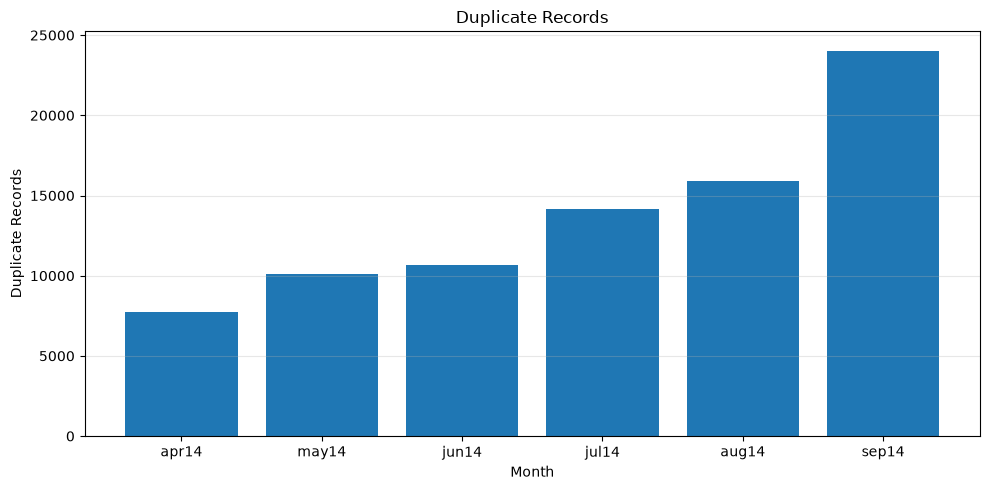

In [ ]:
#Uber Duplicate Records by Month with bar
plt.figure(figsize=(10, 5))

plt.bar(
    quality_df["Month"],
    quality_df["Duplicate Records"]
)

plt.title("Duplicate Records")
plt.xlabel("Month")
plt.ylabel("Duplicate Records")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

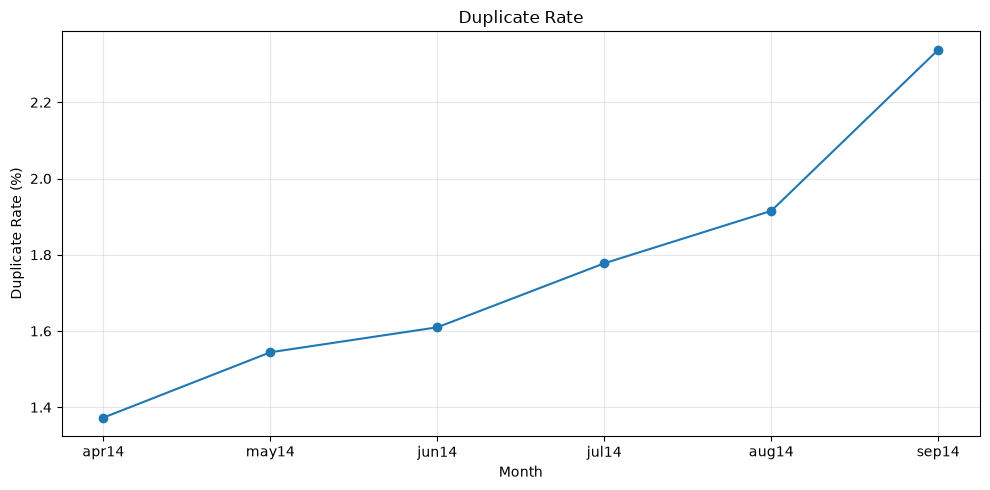

In [ ]:
#Uber Duplicate Rate by Month with plot
lt.figure(figsize=(10, 5))

plt.plot(
    quality_df["Month"],
    quality_df["Duplicate Rate"],
    marker="o"
)

plt.title("Duplicate Rate")
plt.xlabel("Month")
plt.ylabel("Duplicate Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [138]:
# The Base codes are for the following Uber bases: New York City Taxi & Limousine Commission

# B02512 : Unter
# B02598 : Hinter
# B02617 : Weiter
# B02682 : Schmecken
# B02764 : Danach-NY
# B02765 : Grun
# B02835 : Dreist
# B02836 : Drinnen

bases = {"B02512", "B02598", "B02617", "B02682", "B02764", "B02765", "B02835", "B02836"}

invalid_total = {
    "Date/Time": 0,
    "Lat": 0,
    "Lon": 0,
    "Base": 0,
}

for file in files:
    df = pd.read_csv(file)

    dates = pd.to_datetime(
        df["Date/Time"],
        format="%m/%d/%Y %H:%M:%S",
        errors="coerce"
    )

    file_month = pd.to_datetime(
        file.stem[-5:],
        format="%b%y"
    ).to_period("M")

    invalid_date = (
        date.isna() |
        (dates.dt.to_period("M") != file_month)
    ).sum()

    invalid_lat = (~df["Lat"].between(-90, 90)).sum()
    invalid_lon = (~df["Lon"].between(-180, 180)).sum()
    invalid_base = (~df["Base"].isin(bases)).sum()

    invalid_total["Date/Time"] += invalid_date
    invalid_total["Lat"] += invalid_lat
    invalid_total["Lon"] += invalid_lon
    invalid_total["Base"] += invalid_base

    print(f"\nFile: {file.name}")
    print(f"Invalid Date/Time: {invalid_date:,}")
    print(f"Invalid Latitude: {invalid_lat:,}")
    print(f"Invalid Longitude: {invalid_lon:,}")
    print(f"Unexpected Base Codes: {invalid_base:,}")
    print("-" * 40)

print(f"\nTotal Validation Results: ")

for column, count in invalid_total.items():
    print(f"{column}: {count:,}")



File: uber-raw-data-apr14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-may14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-jun14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-jul14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-aug14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-sep14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

Total Validation Results: 
Date/Time: 0
Lat: 

In [139]:
for file in files:
    df = pd.read_csv(file)

    print(f"\nFile: {file.name}")
    print(f"Latitude: {df['Lat'].min()} to {df['Lat'].max()}")
    print(f"Longitude: {df['Lon'].min()} to {df['Lon'].max()}")
    print("-" * 40)


File: uber-raw-data-apr14.csv
Latitude: 40.0729 to 42.1166
Longitude: -74.7733 to -72.0666
----------------------------------------

File: uber-raw-data-may14.csv
Latitude: 40.1067 to 41.3225
Longitude: -74.929 to -72.1801
----------------------------------------

File: uber-raw-data-jun14.csv
Latitude: 39.9558 to 41.3199
Longitude: -74.8594 to -72.6966
----------------------------------------

File: uber-raw-data-jul14.csv
Latitude: 39.7214 to 41.3413
Longitude: -74.826 to -72.3097
----------------------------------------

File: uber-raw-data-aug14.csv
Latitude: 39.6569 to 41.3182
Longitude: -74.7737 to -72.3359
----------------------------------------

File: uber-raw-data-sep14.csv
Latitude: 39.9897 to 41.3476
Longitude: -74.7736 to -72.7163
----------------------------------------


In [ ]:
import geopandas as gpd

nyc = gpd.read_file(data_dir/"Borough_Boundaries_20261028.geojson")
nyc = nyc.to_crs("EPSG:4326")

geo_results = []

for file in files:
    df = pd.read_csv(file)

    points = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(
            df["Lon"],
            df["Lat"]
        ),
        crs="EPSG:4326"
    )

    result = gpd.sjoin(
        points,
        nyc,
        how="left",
        predicate="intersects"
    )

    inside = result.loc[
        result["index_right"].notna()
    ].index.nunique()

    outside = len(df) - inside

    geo_results.append({
        "Month": file.stem.split("-")[-1],
        "Total Records": len(df),
        "Inside NYC": inside,
        "Outside NYC": outside,
        "Outside Rate (%)": outside / len(df) * 100
    })

geo_df = pd.DataFrame(geo_results)

print(geo_df.to_string(index=False))

print("\nTotal Inside NYC:", f"{geo_df['Inside NYC'].sum():,}")
print("Total Outside NYC:", f"{geo_df['Outside NYC'].sum():,}")

Month  Total Records  Inside NYC  Outside NYC  Outside Rate (%)
apr14         564516      551259        13257          2.348383
may14         652435      636695        15740          2.412501
jun14         663844      646174        17670          2.661770
jul14         796121      774931        21190          2.661656
aug14         829275      803730        25545          3.080402
sep14        1028136      999105        29031          2.823654

Total Inside NYC: 4,411,894
Total Outside NYC: 122,433


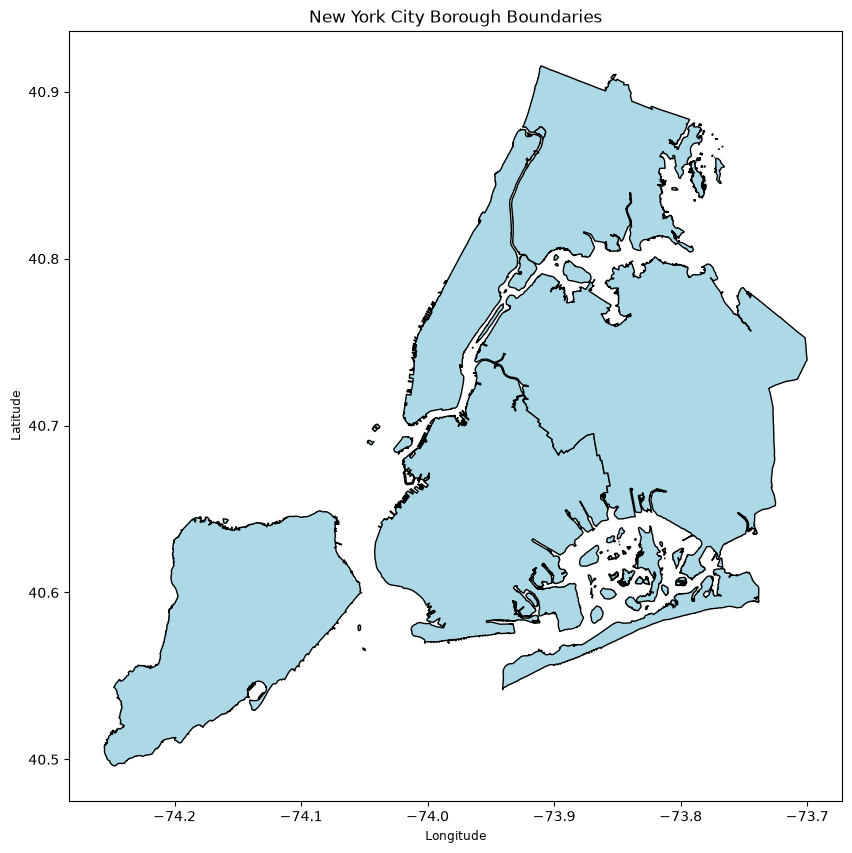

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

nyc.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black"
)

ax.set_title("New York City Borough Boundaries")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

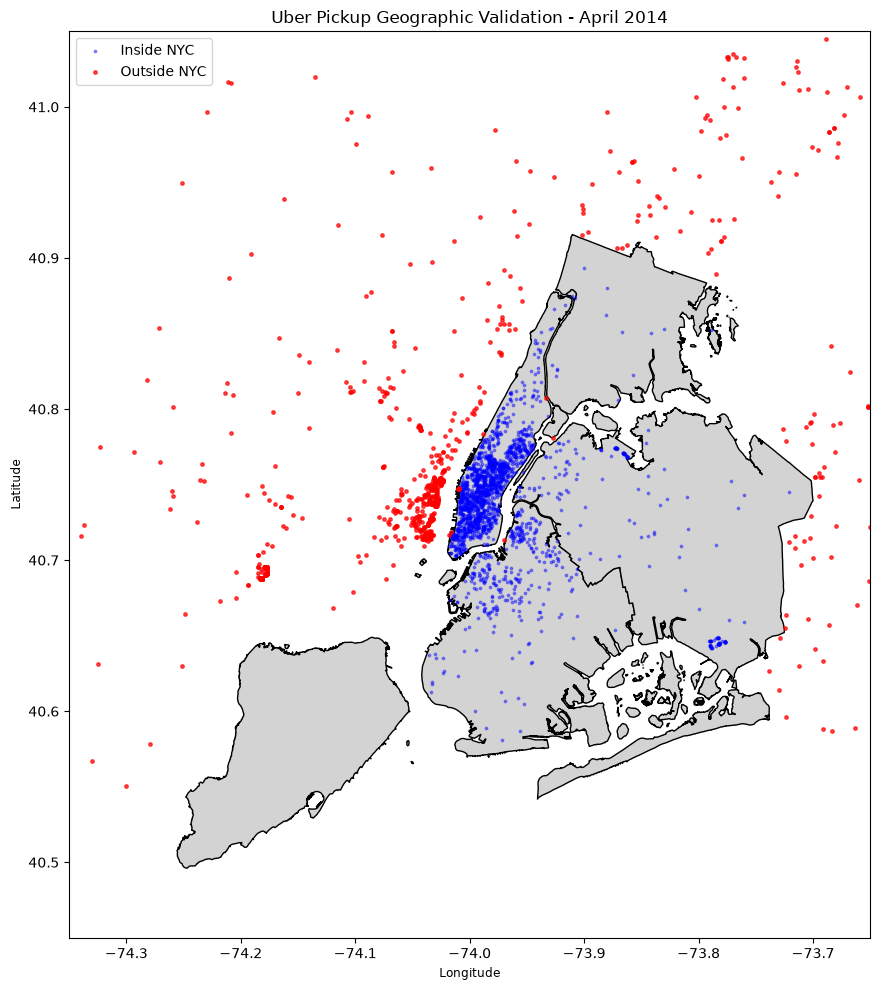

In [ ]:
inside_mask = result["index_right"].notna().groupby(level=0).any()
inside_mask = inside_mask.reindex(points.index, fill_value=False)

inside_points = points.loc[inside_mask]
outside_points = points.loc[~inside_mask]

inside_sample = inside_points.sample(
    n=min(2000, len(inside_points)),
    random_state=42
)

outside_sample = outside_points.sample(
    n=min(1000, len(outside_points)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(10, 10))

nyc.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

inside_sample.plot(
    ax=ax,
    color="blue",
    markersize=3,
    alpha=0.4,
    label="Inside NYC"
)

outside_sample.plot(
    ax=ax,
    color="red",
    markersize=6,
    alpha=0.7,
    label="Outside NYC"
)

ax.set_xlim(-74.35, -73.65)
ax.set_ylim(40.45, 41.05)

ax.set_title("Uber Pickup Geographic Validation - April 2014")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()

plt.tight_layout()
plt.show()

In [159]:
usa = gpd.read_file(
    data_dir / "boundaries/cb_2014_us_state_500k.shp"
)

print(usa.head())
print("\nCRS:", usa.crs)
print("\nTotal geographic areas:", len(usa))

  STATEFP   STATENS     AFFGEOID GEOID STUSPS                  NAME LSAD  \
0      02  01785533  0400000US02    02     AK                Alaska   00   
1      04  01779777  0400000US04    04     AZ               Arizona   00   
2      08  01779779  0400000US08    08     CO              Colorado   00   
3      09  01779780  0400000US09    09     CT           Connecticut   00   
4      11  01702382  0400000US11    11     DC  District of Columbia   00   

           ALAND        AWATER  \
0  1477849359548  245487700921   
1   294205282243    1027790845   
2   268426928342    1176085119   
3    12542396439    1814978794   
4      158350578      18633500   

                                            geometry  
0  MULTIPOLYGON Z (((-157.90396 56.34644 0, -157....  
1  POLYGON Z ((-114.81629 32.50804 0, -114.81432 ...  
2  POLYGON Z ((-109.06025 38.59933 0, -109.05954 ...  
3  MULTIPOLYGON Z (((-72.76143 41.24233 0, -72.75...  
4  POLYGON Z ((-77.11976 38.93434 0, -77.11253 38...  

CRS: EP

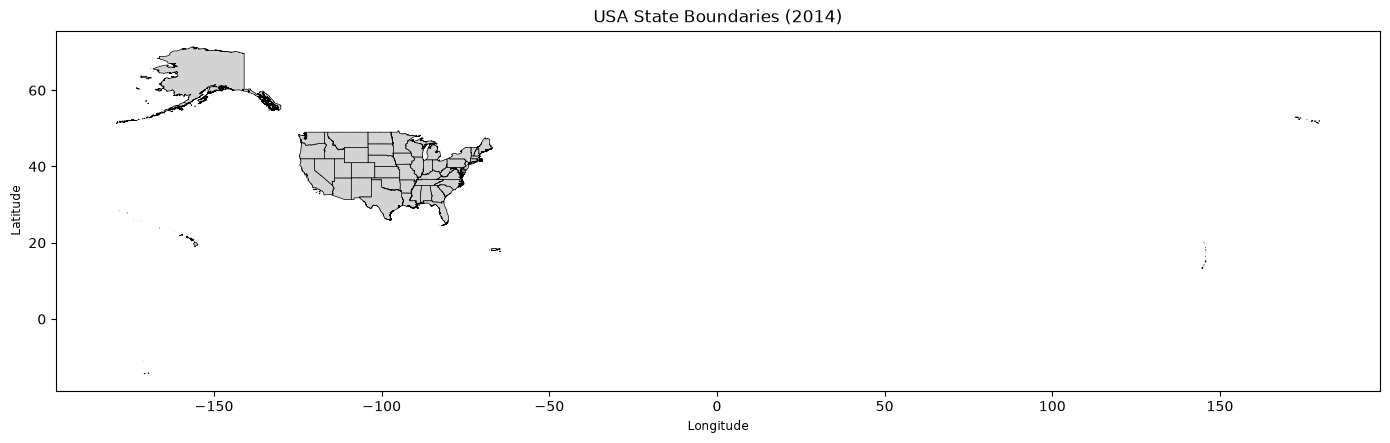

In [ ]:
usa = usa.to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(14, 8))

usa.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title("USA State Boundaries (2014)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


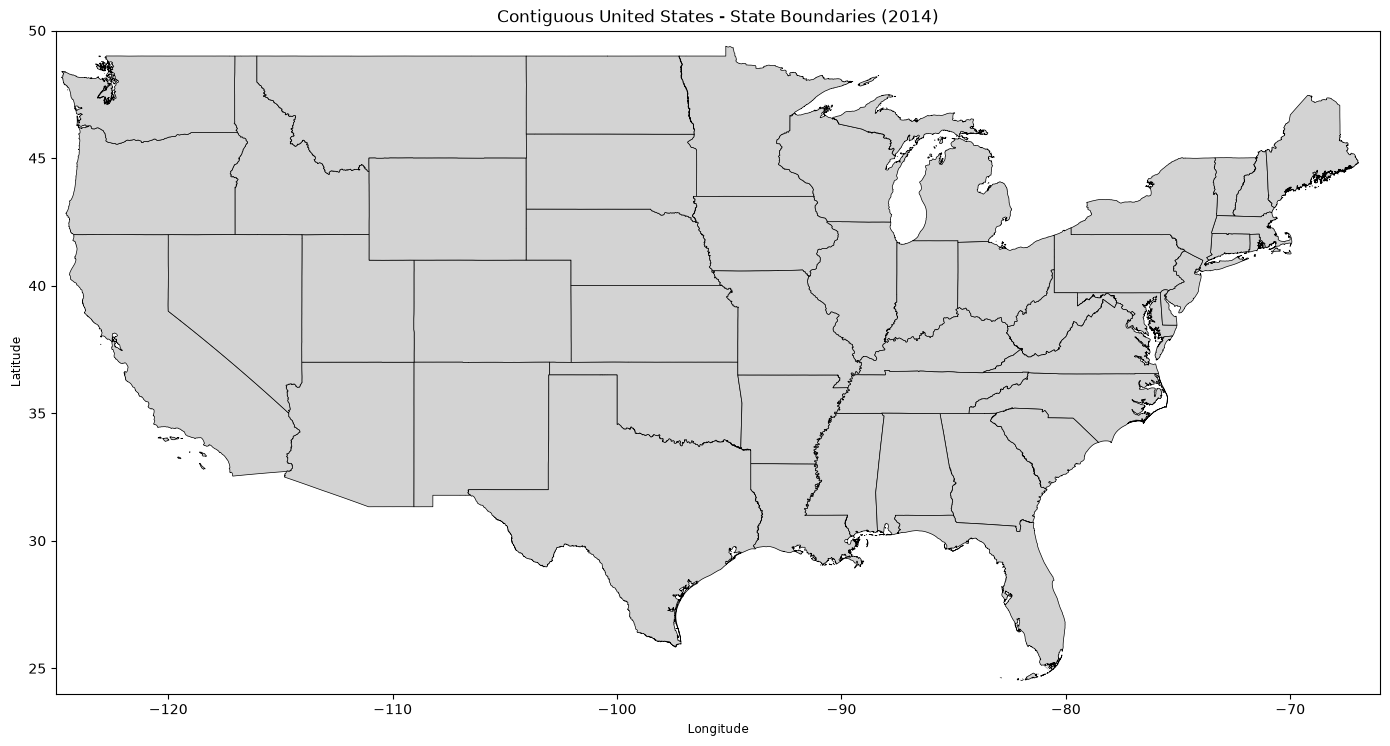

In [ ]:
fig, ax = plt.subplots(figsize=(14, 8))

usa.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)

ax.set_title("Contiguous United States - State Boundaries (2014)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


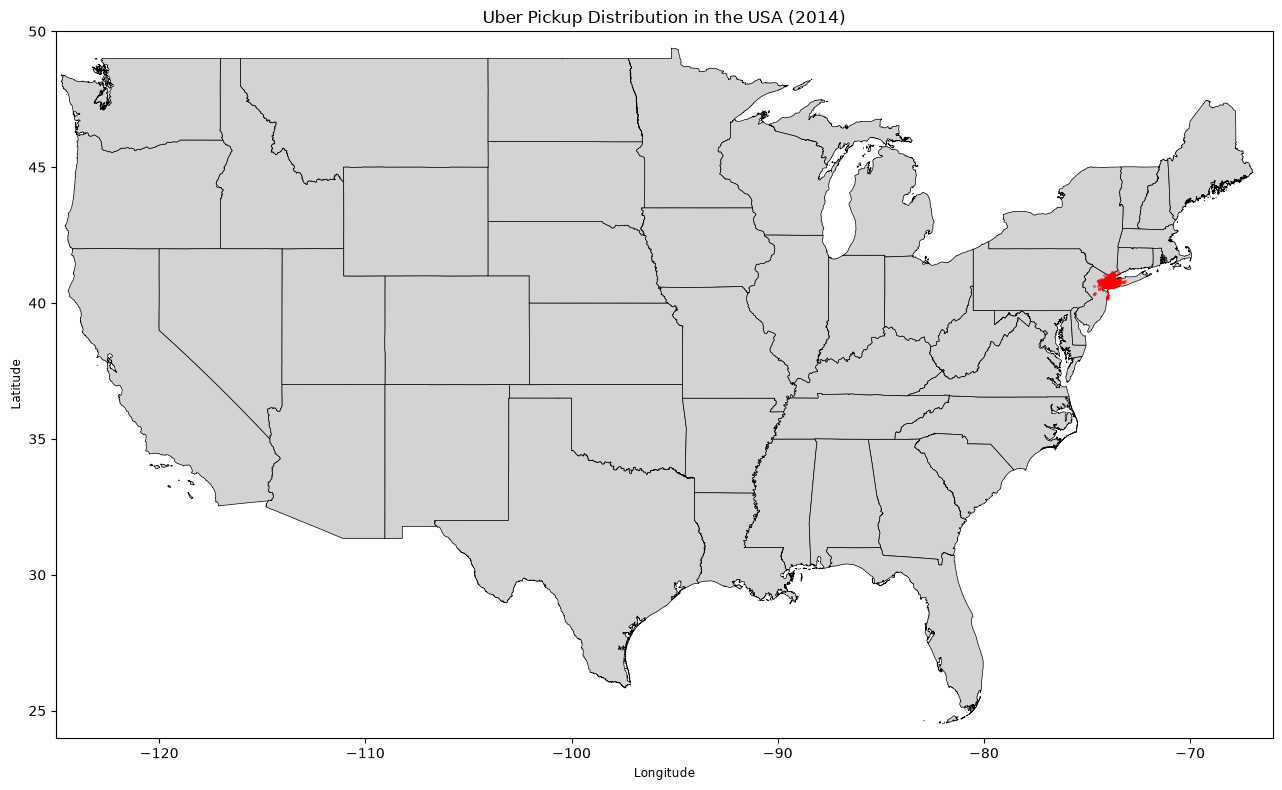

In [ ]:
samples = []

for file in files:
    df = pd.read_csv(file)

    sample = df.sample(
        n=min(5000, len(df)),
        random_state=42
    )

    samples.append(sample)

uber_sample = pd.concat(
    samples,
    ignore_index=True
)

uber_points = gpd.GeoDataFrame(
    uber_sample,
    geometry=gpd.points_from_xy(
        uber_sample["Lon"],
        uber_sample["Lat"]
    ),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(14, 8))

usa.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

uber_points.plot(
    ax=ax,
    color="red",
    markersize=2,
    alpha=0.4
)

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)

ax.set_title("Uber Pickup Distribution in the USA (2014)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


In [164]:
print(usa.columns.tolist())

print(usa[["NAME", "STUSPS"]])

['STATEFP', 'STATENS', 'AFFGEOID', 'GEOID', 'STUSPS', 'NAME', 'LSAD', 'ALAND', 'AWATER', 'geometry']
                                            NAME STUSPS
0                                         Alaska     AK
1                                        Arizona     AZ
2                                       Colorado     CO
3                                    Connecticut     CT
4                           District of Columbia     DC
5                                        Georgia     GA
6                                          Idaho     ID
7                                       Illinois     IL
8                                        Indiana     IN
9                                         Kansas     KS
10                                      Kentucky     KY
11                                      Maryland     MD
12                                     Minnesota     MN
13                                   Mississippi     MS
14                                       Montana     MT
15 

In [ ]:
state_results = []
unmatched_total = 0

states = usa[["NAME", "STUSPS", "geometry"]].to_crs("EPSG:4326")

for file in files:
    df = pd.read_csv(file)

    points = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(
            df["Lon"],
            df["Lat"]
        ),
        crs="EPSG:4326"
    )

    joined = gpd.sjoin(
        points,
        states,
        how="left",
        predicate="intersects"
    )

    state_per_pickup = joined.groupby(level=0)["NAME"].first()

    unmatched = state_per_pickup.isna().sum()
    unmatched_total += unmatched

    counts = state_per_pickup.value_counts()

    for state, count in counts.items():
        state_results.append({
            "Month": file.stem.split("-")[-1],
            "State": state,
            "Pickup Records": count
        })

    print(f"{file.name}")
    print(f"Matched: {len(df) - unmatched:,}")
    print(f"Unmatched: {unmatched:,}")
    print("-" * 40)

state_df = pd.DataFrame(state_results)

state_summary = (
    state_df.groupby("State")["Pickup Records"]
    .sum()
    .sort_values(ascending=False)
)

print("\nPickup Records by State:")
print(state_summary)

print(f"\nTotal Unmatched Records: {unmatched_total:,}")

uber-raw-data-apr14.csv
Matched: 564,512
Unmatched: 4
----------------------------------------
uber-raw-data-may14.csv
Matched: 652,426
Unmatched: 9
----------------------------------------
uber-raw-data-jun14.csv
Matched: 663,839
Unmatched: 5
----------------------------------------
uber-raw-data-jul14.csv
Matched: 796,107
Unmatched: 14
----------------------------------------
uber-raw-data-aug14.csv
Matched: 829,262
Unmatched: 13
----------------------------------------
uber-raw-data-sep14.csv
Matched: 1,028,117
Unmatched: 19
----------------------------------------

Pickup Records by State:
State
New York         4441067
New Jersey         92649
Connecticut          546
Massachusetts          1
Name: Pickup Records, dtype: int64

Total Unmatched Records: 64


In [166]:
print("State Summary:", state_summary.sum())
print("Unmatched:", unmatched_total)

print(
    "Reconciled Total:",
    state_summary.sum() + unmatched_total
)

State Summary: 4534263
Unmatched: 64
Reconciled Total: 4534327


In [167]:
print("Columns:", nyc.columns.tolist())
print("CRS:", nyc.crs)
print("Total polygons:", len(nyc))

display(nyc.head())

Columns: [':id', ':version', ':created_at', ':updated_at', 'borocode', 'boroname', 'shape_area', 'shape_leng', 'geometry']
CRS: EPSG:4326
Total polygons: 5


,:id,:version,:created_at,:updated_at,borocode,boroname,shape_area,shape_leng,geometry
0,row-7tjt.uvyw.7ibt,rv-4t64_6m9c_35an,2026-05-26 19:35:49.449+00:00,2026-05-26 19:35:49.449+00:00,5,Staten Island,1623618358.46,325912.288988,"MULTIPOLYGON (((-74.05051 40.56642, -74.05047 ..."
1,row-j4kv.jskm_sgt9,rv-86hu-khv5~6gub,2026-05-26 19:35:49.449+00:00,2026-05-26 19:35:49.449+00:00,3,Brooklyn,1934462607.75,726953.04509,"MULTIPOLYGON (((-73.86327 40.58388, -73.86381 ..."
2,row-fmcn_egr2.4ed7,rv-fzx7_87v2_ghcm,2026-05-26 19:35:49.449+00:00,2026-05-26 19:35:49.449+00:00,4,Queens,3041419716.32,887902.903727,"MULTIPOLYGON (((-73.82645 40.59053, -73.82642 ..."
3,row-sgcq-gqfx_iqid,rv-n78r-xzdj~m3tb,2026-05-26 19:35:49.449+00:00,2026-05-26 19:35:49.449+00:00,1,Manhattan,636631537.285,359537.906171,"MULTIPOLYGON (((-74.01093 40.68449, -74.01193 ..."
4,row-xiai_c2ui_hanx,rv-4ed5_kbz3-4cqg,2026-05-26 19:35:49.449+00:00,2026-05-26 19:35:49.449+00:00,2,Bronx,1187199168.58,463146.326689,"MULTIPOLYGON (((-73.89681 40.79581, -73.89694 ..."


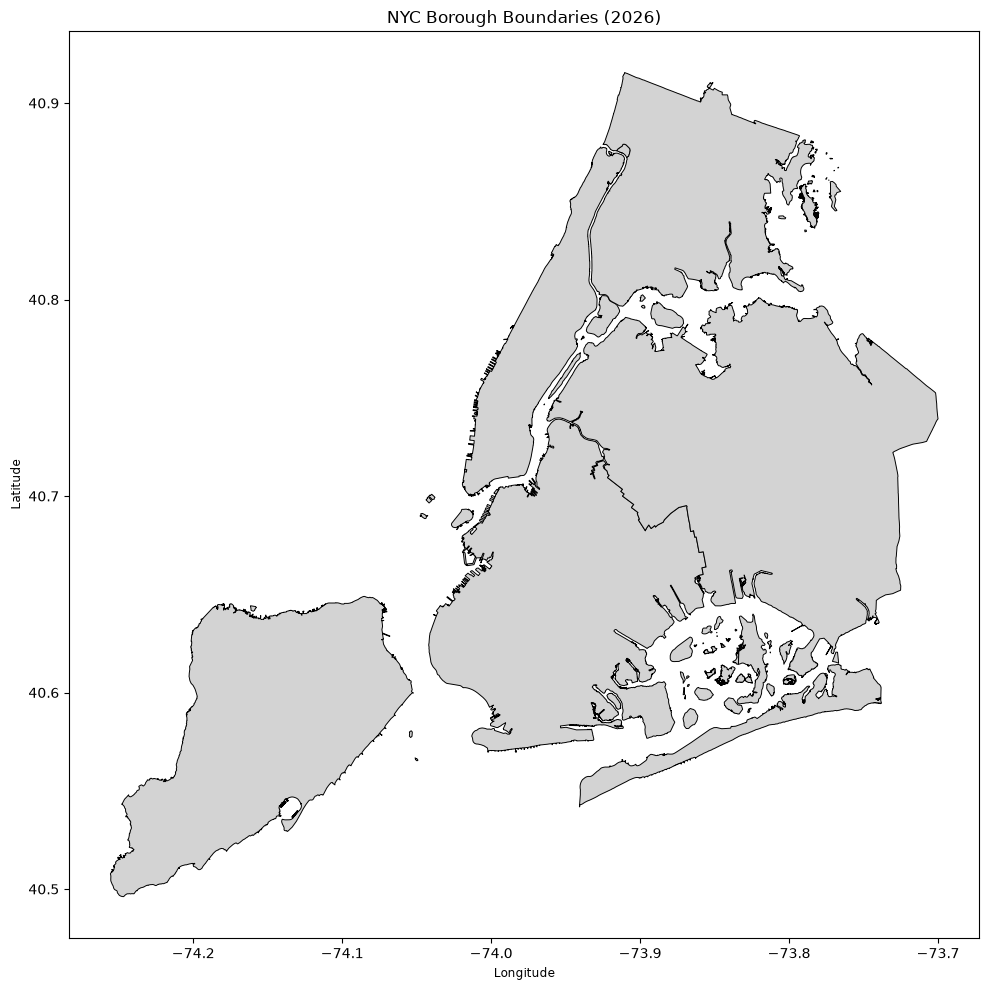

In [175]:
fig, ax = plt.subplots(figsize=(10, 10))

nyc.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.7
)

ax.set_title("NYC Borough Boundaries (2026)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [170]:
borough_results = []
boundary = nyc[["boroname", "geometry"]].copy()

for file in files:
    df = pd.read_csv(file)

    points = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(
            df["Lon"],
            df["Lat"]
        ),
        crs="EPSG:4326"
    )

    joined = gpd.sjoin(
        points,
        boundary,
        how="left",
        predicate="intersects"
    )

    matches = joined.groupby(level=0)["boroname"].first()
    matches = matches.reindex(df.index)

    counts = matches.fillna("Outside NYC").value_counts()

    for borough, count in counts.items():
        borough_results.append({
            "Month": file.stem.split("-")[-1],
            "Borough": borough,
            "Pickup Records": count,
            "Percentage (%)": count / len(df) * 100
        })

borough_df = pd.DataFrame(borough_results)

borough_summary = (
    borough_df.groupby("Borough", as_index=False)["Pickup Records"]
    .sum()
    .sort_values("Pickup Records", ascending=False)
)

total_records = borough_summary["Pickup Records"].sum()

borough_summary["Percentage (%)"] = (
    borough_summary["Pickup Records"] / total_records * 100
)

borough_summary["Percentage (%)"] = (
    borough_summary["Percentage (%)"].round(2)
)

print("Pickup Records by Borough:")
print(borough_summary.to_string(index=False))

print(f"\nTotal Records: {total_records:,}")
print(f"Total Percentage: {borough_summary['Percentage (%)'].sum():.2f}%")
print(f"Record Reconciliation: {total_records == 4534327}")

Pickup Records by Borough:
      Borough  Pickup Records  Percentage (%)
    Manhattan         3443457           75.94
     Brooklyn          593595           13.09
       Queens          342224            7.55
  Outside NYC          122433            2.70
        Bronx           31584            0.70
Staten Island            1034            0.02

Total Records: 4,534,327
Total Percentage: 100.00%
Record Reconciliation: True


In [171]:
outside_by_state = []
ambiguous_state_total = 0
ambiguous_borough_total = 0

states = usa[["NAME", "geometry"]].to_crs("EPSG:4326")
boroughs = nyc[["boroname", "geometry"]].to_crs("EPSG:4326")

for file in files:
    df = pd.read_csv(file)

    points = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df["Lon"], df["Lat"]),
        crs="EPSG:4326"
    )

    state_join = gpd.sjoin(
        points, states, how="left", predicate="intersects"
    )

    borough_join = gpd.sjoin(
        points, boroughs, how="left", predicate="intersects"
    )

    state_matches = state_join.groupby(level=0)["NAME"].agg(
        lambda x: x.dropna().nunique()
    )

    borough_matches = borough_join.groupby(level=0)["boroname"].agg(
        lambda x: x.dropna().nunique()
    )

    ambiguous_state_total += (state_matches > 1).sum()
    ambiguous_borough_total += (borough_matches > 1).sum()

    state_label = (
        state_join.groupby(level=0)["NAME"]
        .first()
        .reindex(df.index)
        .fillna("Unmatched State")
    )

    borough_label = (
        borough_join.groupby(level=0)["boroname"]
        .first()
        .reindex(df.index)
    )

    outside_mask = borough_label.isna()
    outside_states = state_label.loc[outside_mask]

    for state, count in outside_states.value_counts().items():
        outside_by_state.append({
            "Month": file.stem.split("-")[-1],
            "State": state,
            "Pickup Records": count
        })

outside_df = pd.DataFrame(outside_by_state)

outside_summary = (
    outside_df.groupby("State", as_index=False)["Pickup Records"]
    .sum()
    .sort_values("Pickup Records", ascending=False)
)

outside_total = outside_summary["Pickup Records"].sum()

outside_summary["Percentage (%)"] = (
    outside_summary["Pickup Records"] / outside_total * 100
).round(2)

print("Outside NYC Records by State:")
print(outside_summary.to_string(index=False))

print(f"\nTotal Outside NYC: {outside_total:,} (100.00%)")
print(f"Outside NYC Rate: {outside_total / 4534327 * 100:.2f}%")
print(f"Matches Previous Result: {outside_total == 122433}")

print(f"\nAmbiguous State Matches: {ambiguous_state_total:,}")
print(f"Ambiguous Borough Matches: {ambiguous_borough_total:,}")


Outside NYC Records by State:
          State  Pickup Records  Percentage (%)
     New Jersey           92649           75.67
       New York           29188           23.84
    Connecticut             546            0.45
Unmatched State              49            0.04
  Massachusetts               1            0.00

Total Outside NYC: 122,433 (100.00%)
Outside NYC Rate: 2.70%
Matches Previous Result: True

Ambiguous State Matches: 0
Ambiguous Borough Matches: 0


In [172]:
suspicious_records = []
total_records = 0

states = usa[["NAME", "geometry"]].to_crs("EPSG:4326")
boroughs = nyc[["boroname", "geometry"]].to_crs("EPSG:4326")

for file in files:
    df = pd.read_csv(file)
    total_records += len(df)

    points = gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df["Lon"], df["Lat"]),
        crs="EPSG:4326"
    )

    state_join = gpd.sjoin(
        points,
        states,
        how="left",
        predicate="intersects"
    )

    borough_join = gpd.sjoin(
        points,
        boroughs,
        how="left",
        predicate="intersects"
    )

    state_label = (
        state_join.groupby(level=0)["NAME"]
        .first()
        .reindex(df.index)
    )

    borough_label = (
        borough_join.groupby(level=0)["boroname"]
        .first()
        .reindex(df.index)
    )

    outside_nyc = borough_label.isna()
    unmatched_state = state_label.isna()
    massachusetts = state_label.eq("Massachusetts")

    suspicious_mask = (
        unmatched_state | (outside_nyc & massachusetts)
    )

    flagged = df.loc[suspicious_mask].copy()

    flagged["Month"] = file.stem.split("-")[-1]

    flagged["State"] = (
        state_label.loc[suspicious_mask]
        .fillna("Unmatched State")
    )

    flagged["Borough"] = (
        borough_label.loc[suspicious_mask]
        .fillna("Outside NYC")
    )

    flagged["Reason"] = "Unmatched State"

    flagged.loc[
        flagged["State"].eq("Massachusetts"),
        "Reason"
    ] = "Massachusetts Pickup"

    flagged.loc[
        flagged["State"].eq("Unmatched State")
        & flagged["Borough"].ne("Outside NYC"),
        "Reason"
    ] = "Inside NYC but Unmatched State"

    suspicious_records.append(flagged)

suspicious_df = pd.concat(
    suspicious_records,
    ignore_index=True
)

reason_summary = (
    suspicious_df["Reason"]
    .value_counts()
    .rename_axis("Reason")
    .reset_index(name="Records")
)

reason_summary["Percentage (%)"] = (
    reason_summary["Records"] / total_records * 100
).round(5)

print("Suspicious Records by Reason:")
print(reason_summary.to_string(index=False))

print(f"\nTotal Suspicious Records: {len(suspicious_df):,}")
print(f"Percentage of Dataset: {len(suspicious_df) / total_records * 100:.5f}%")
print(f"Expected 65 Records: {len(suspicious_df) == 65}")

display(
    suspicious_df[
        ["Month", "Date/Time", "Lat", "Lon", "Base",
         "State", "Borough", "Reason"]
    ]
)


Suspicious Records by Reason:
                        Reason  Records  Percentage (%)
               Unmatched State       49         0.00108
Inside NYC but Unmatched State       15         0.00033
          Massachusetts Pickup        1         0.00002

Total Suspicious Records: 65
Percentage of Dataset: 0.00143%
Expected 65 Records: True


,Month,Date/Time,Lat,Lon,Base,State,Borough,Reason
0,apr14,4/20/2014 8:32:00,42.1166,-72.0666,B02598,Massachusetts,Outside NYC,Massachusetts Pickup
1,apr14,4/1/2014 3:22:00,40.5748,-73.9524,B02617,Unmatched State,Brooklyn,Inside NYC but Unmatched State
2,apr14,4/5/2014 17:16:00,40.6886,-74.0068,B02617,Unmatched State,Outside NYC,Unmatched State
3,apr14,4/9/2014 4:46:00,40.7020,-74.0173,B02682,Unmatched State,Outside NYC,Unmatched State
4,apr14,4/20/2014 0:07:00,40.7013,-74.0160,B02682,Unmatched State,Outside NYC,Unmatched State
...,...,...,...,...,...,...,...,...
60,sep14,9/30/2014 20:04:00,40.7003,-74.0148,B02617,Unmatched State,Outside NYC,Unmatched State
61,sep14,9/17/2014 21:05:00,40.9076,-73.7602,B02682,Unmatched State,Outside NYC,Unmatched State
62,sep14,9/2/2014 12:59:00,40.6056,-74.0479,B02764,Unmatched State,Outside NYC,Unmatched State
63,sep14,9/10/2014 19:13:00,40.6998,-74.0026,B02764,Unmatched State,Outside NYC,Unmatched State


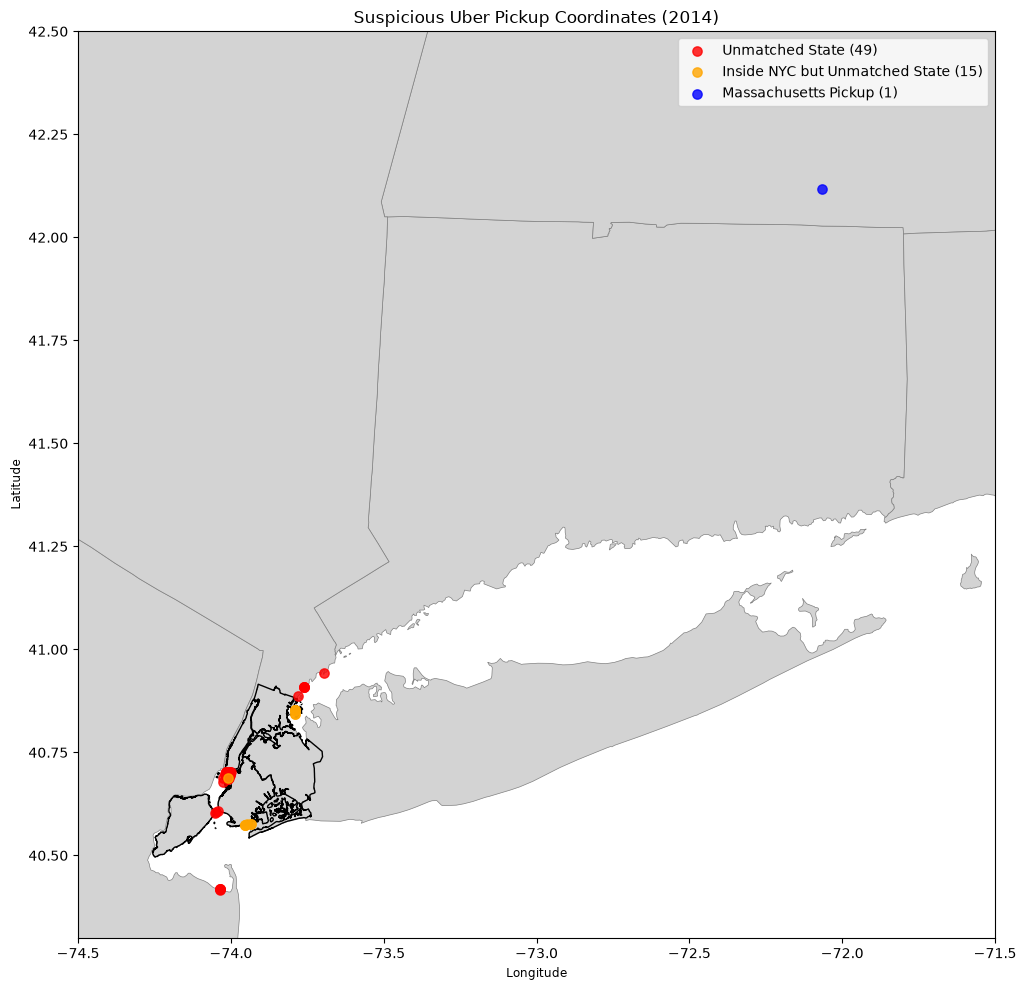

In [176]:

import matplotlib.pyplot as plt
import geopandas as gpd

suspicious_points = gpd.GeoDataFrame(
    suspicious_df,
    geometry=gpd.points_from_xy(
        suspicious_df["Lon"],
        suspicious_df["Lat"]
    ),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(11, 10))

usa.plot(
    ax=ax,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.5
)

nyc.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1
)

styles = {
    "Unmatched State": "red",
    "Inside NYC but Unmatched State": "orange",
    "Massachusetts Pickup": "blue"
}

for reason, color in styles.items():
    subset = suspicious_points[
        suspicious_points["Reason"] == reason
    ]

    subset.plot(
        ax=ax,
        color=color,
        markersize=45,
        alpha=0.8,
        label=f"{reason} ({len(subset):,})"
    )

ax.set_xlim(-74.5, -71.5)
ax.set_ylim(40.3, 42.5)

ax.set_title(
    "Suspicious Uber Pickup Coordinates (2014)"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()

plt.tight_layout()
plt.show()
